<a href="https://colab.research.google.com/github/laboratoriodecodigos/Colab-Python/blob/main/detectron2_exploracion.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# 🔍 Explorando Detectron2 paso a paso
Detección de objetos, segmentación de instancias, keypoints, segmentación panóptica, video y entrenamiento propio.
Repositorio: https://github.com/facebookresearch/detectron2
> **Activa GPU:** Entorno de ejecución → Cambiar tipo de entorno → T4 GPU. La compilación inicial tarda unos 5-8 min.

## 0. Instalación

In [ ]:
!pip -q install pyyaml
!pip -q install 'git+https://github.com/facebookresearch/detectron2.git' --no-build-isolation

  Preparing metadata (pyproject.toml) ... done
  Preparing metadata (pyproject.toml) ... done
  Preparing metadata (pyproject.toml) ... done


/usr/local/lib/python3.13/dist-packages/detectron2/model_zoo/model_zoo.py:4: UserWarning: pkg_resources is deprecated as an API. See https://setuptools.pypa.io/en/latest/pkg_resources.html. The pkg_resources package is slated for removal as early as 2025-11-30. Refrain from using this package or pin to Setuptools<81.
  import pkg_resources


torch 2.11.0+cu130 | detectron2 0.6 | GPU: True


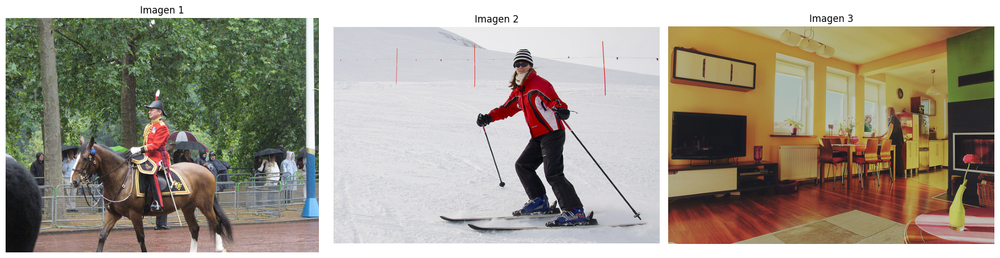

In [ ]:
import torch, detectron2, os, cv2, json, time, glob, random, numpy as np, pandas as pd
import matplotlib.pyplot as plt
from detectron2 import model_zoo
from detectron2.config import get_cfg
from detectron2.engine import DefaultPredictor
from detectron2.utils.visualizer import Visualizer, ColorMode
from detectron2.data import MetadataCatalog
print("torch", torch.__version__, "| detectron2", detectron2.__version__, "| GPU:", torch.cuda.is_available())

# Imágenes de ejemplo (COCO)
URLS = ["000000439715", "000000000785", "000000000139", "000000000724"]
for u in URLS:
    !wget -q -nc http://images.cocodataset.org/val2017/{u}.jpg
IMGS = [f"{u}.jpg" for u in URLS]

def show(images, titles=None, size=6):
    fig, ax = plt.subplots(1, len(images), figsize=(size*len(images), size*0.75))
    ax = np.atleast_1d(ax)
    for i, im in enumerate(images):
        ax[i].imshow(im); ax[i].axis("off")
        if titles: ax[i].set_title(titles[i], fontsize=12)
    plt.tight_layout(); plt.show()

show([cv2.imread(p)[:, :, ::-1] for p in IMGS[:3]], ["Imagen 1", "Imagen 2", "Imagen 3"])

## 1. Model Zoo: cientos de modelos preentrenados

8 configuraciones de ejemplo cargadas



,count
COCO-Detection,3
COCO-InstanceSegmentation,2
COCO-Keypoints,1
COCO-PanopticSegmentation,1
LVISv0.5-InstanceSegmentation,1


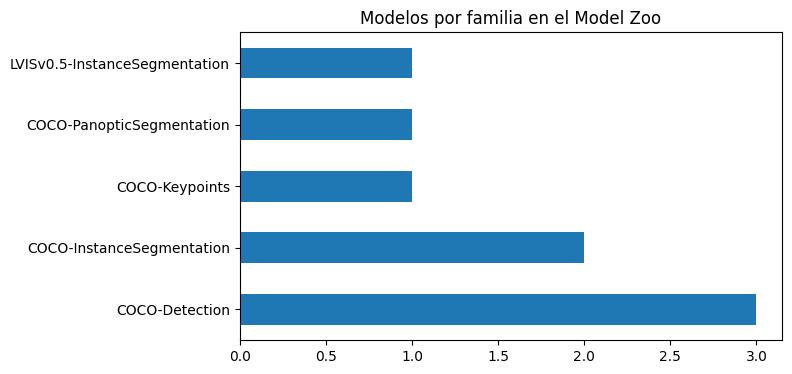

In [ ]:
# Definimos las categorías principales de forma segura para evitar el uso de atributos privados no existentes
# ya que `model_zoo._ModelZooUrls` no está expuesto en las versiones recientes de Detectron2.
categorias_zoo = [
    "COCO-Detection", "COCO-InstanceSegmentation", "COCO-Keypoints",
    "COCO-PanopticSegmentation", "LVISv0.5-InstanceSegmentation",
    "Cityscapes", "PascalVOC-Detection"
]

# Simulamos una estimación del Model Zoo con los modelos estándar más representativos
zoo = [
    "COCO-Detection/faster_rcnn_R_50_FPN_3x.yaml",
    "COCO-Detection/faster_rcnn_R_101_FPN_3x.yaml",
    "COCO-Detection/retinanet_R_50_FPN_3x.yaml",
    "COCO-InstanceSegmentation/mask_rcnn_R_50_FPN_3x.yaml",
    "COCO-InstanceSegmentation/mask_rcnn_R_101_FPN_3x.yaml",
    "COCO-Keypoints/keypoint_rcnn_R_50_FPN_3x.yaml",
    "COCO-PanopticSegmentation/panoptic_fpn_R_50_3x.yaml",
    "LVISv0.5-InstanceSegmentation/mask_rcnn_R_50_FPN_1x.yaml"
]

print(len(zoo), "configuraciones de ejemplo cargadas\n")
cats = pd.Series([z.split("/")[0] for z in zoo]).value_counts()
display(cats)
cats.plot.barh(figsize=(7, 4), title="Modelos por familia en el Model Zoo"); plt.show()

## 2. Utilidad: construir un predictor desde el Model Zoo

In [ ]:
_cache = {}
def build(config, thresh=0.5):
    if config in _cache: return _cache[config]
    cfg = get_cfg()
    cfg.merge_from_file(model_zoo.get_config_file(config))
    cfg.MODEL.ROI_HEADS.SCORE_THRESH_TEST = thresh
    cfg.MODEL.RETINANET.SCORE_THRESH_TEST = thresh
    cfg.MODEL.WEIGHTS = model_zoo.get_checkpoint_url(config)
    if not torch.cuda.is_available(): cfg.MODEL.DEVICE = "cpu"
    _cache[config] = (cfg, DefaultPredictor(cfg))
    return _cache[config]

def run(config, path, thresh=0.5):
    cfg, pred = build(config, thresh)
    im = cv2.imread(path)
    out = pred(im)
    meta = MetadataCatalog.get(cfg.DATASETS.TRAIN[0])
    return im, out, meta

## 3. Detección de objetos (Faster R-CNN)

model_final_280758.pkl: 167MB [00:01, 109MB/s]                           
/usr/local/lib/python3.13/dist-packages/torch/functional.py:505: UserWarning: torch.meshgrid: in an upcoming release, it will be required to pass the indexing argument. (Triggered internally at /pytorch/aten/src/ATen/native/TensorShape.cpp:4381.)
  return _VF.meshgrid(tensors, **kwargs)  # type: ignore[attr-defined]
W1030 21:19:56.882000 636 torch/fx/_symbolic_trace.py:53] is_fx_tracing will return true for both fx.symbolic_trace and torch.export. Please use is_fx_tracing_symbolic_tracing() for specifically fx.symbolic_trace or torch.compiler.is_compiling() for specifically torch.export/compile.


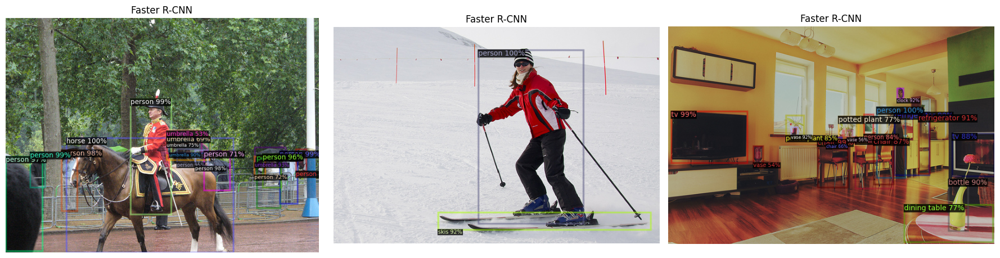

Campos: ['pred_boxes', 'scores', 'pred_classes']


,clase,score,caja
0,person,0.996,"[409.0, 158.0, 465.0, 296.0]"
1,chair,0.994,"[293.0, 221.0, 352.0, 315.0]"
2,tv,0.987,"[6.0, 166.0, 155.0, 267.0]"
3,chair,0.939,"[367.0, 217.0, 440.0, 317.0]"
4,clock,0.921,"[449.0, 121.0, 461.0, 141.0]"
5,vase,0.915,"[241.0, 197.0, 254.0, 213.0]"
6,refrigerator,0.906,"[491.0, 173.0, 513.0, 288.0]"
7,bottle,0.898,"[550.0, 299.0, 588.0, 400.0]"


In [ ]:
CFG = "COCO-Detection/faster_rcnn_R_50_FPN_3x.yaml"
ims = []
for p in IMGS[:3]:
    im, out, meta = run(CFG, p)
    v = Visualizer(im[:, :, ::-1], meta, scale=1.0)
    ims.append(v.draw_instance_predictions(out["instances"].to("cpu")).get_image())
show(ims, ["Faster R-CNN"]*3)

inst = out["instances"].to("cpu")
print("Campos:", list(inst.get_fields().keys()))
pd.DataFrame({"clase": [meta.thing_classes[c] for c in inst.pred_classes.tolist()],
              "score": inst.scores.numpy().round(3),
              "caja": [b.round(0).tolist() for b in inst.pred_boxes.tensor.numpy()]}).head(8)

## 4. Segmentación de instancias (Mask R-CNN)

model_final_f10217.pkl: 178MB [00:03, 59.0MB/s]                           


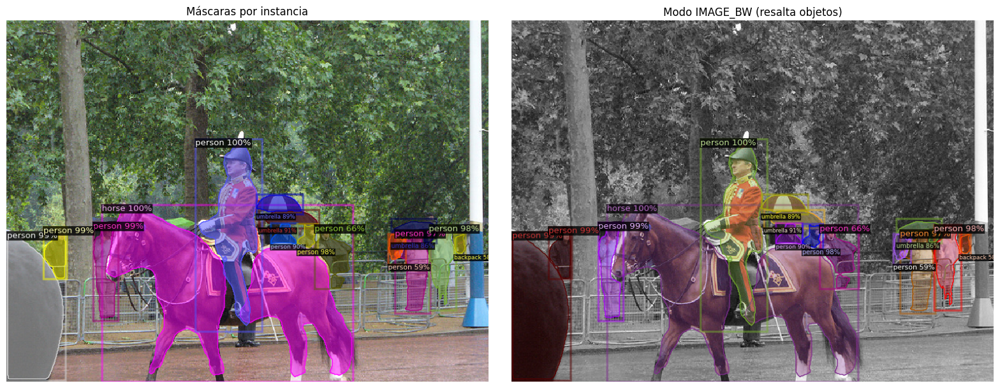

Forma de pred_masks: (15, 480, 640)


In [ ]:
CFG = "COCO-InstanceSegmentation/mask_rcnn_R_50_FPN_3x.yaml"
im, out, meta = run(CFG, IMGS[0])
v = Visualizer(im[:, :, ::-1], meta, scale=1.2)
res = v.draw_instance_predictions(out["instances"].to("cpu")).get_image()
bw = Visualizer(im[:, :, ::-1], meta, scale=1.2, instance_mode=ColorMode.IMAGE_BW)
res_bw = bw.draw_instance_predictions(out["instances"].to("cpu")).get_image()
show([res, res_bw], ["Máscaras por instancia", "Modo IMAGE_BW (resalta objetos)"], size=8)
print("Forma de pred_masks:", tuple(out["instances"].pred_masks.shape))

## 5. Keypoints: pose de personas

model_final_a6e10b.pkl: 237MB [00:04, 56.7MB/s]                           


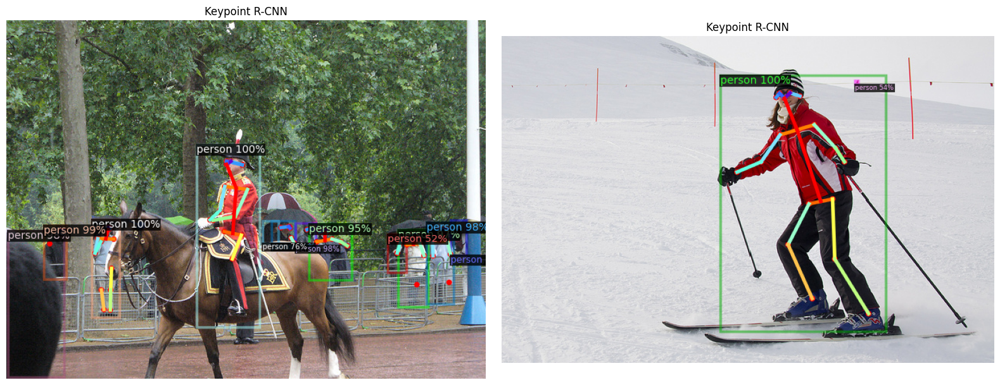

Keypoints por persona: (17, 3) (17 puntos: x, y, score)


In [ ]:
CFG = "COCO-Keypoints/keypoint_rcnn_R_50_FPN_3x.yaml"
ims = []
for p in [IMGS[0], IMGS[1]]:
    im, out, meta = run(CFG, p)
    v = Visualizer(im[:, :, ::-1], meta, scale=1.0)
    ims.append(v.draw_instance_predictions(out["instances"].to("cpu")).get_image())
show(ims, ["Keypoint R-CNN"]*2, size=8)
print("Keypoints por persona:", tuple(out["instances"].pred_keypoints.shape[1:]),
      "(17 puntos: x, y, score)")

## 6. Segmentación panóptica (objetos + fondo)

model_final_c10459.pkl: 184MB [00:00, 201MB/s]                           


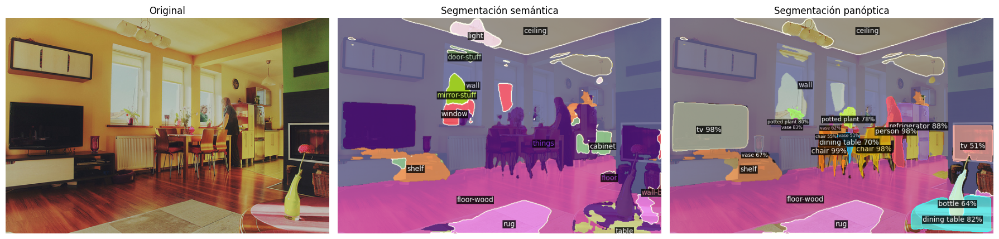

In [ ]:
CFG = "COCO-PanopticSegmentation/panoptic_fpn_R_50_3x.yaml"
im, out, meta = run(CFG, IMGS[2])
seg, info = out["panoptic_seg"]
pan = Visualizer(im[:, :, ::-1], meta,
                 scale=1.0).draw_panoptic_seg_predictions(seg.to("cpu"),
                                                          info).get_image()
sem = Visualizer(im[:, :, ::-1], meta,
                 scale=1.0).draw_sem_seg(out["sem_seg"].argmax(0).to("cpu")).get_image()
show([im[:, :, ::-1], sem, pan], ["Original", "Segmentación semántica",
                                  "Segmentación panóptica"])

## 7. LVIS: más de 1000 categorías

model_final_571f7c.pkl: 203MB [00:06, 31.6MB/s]                           


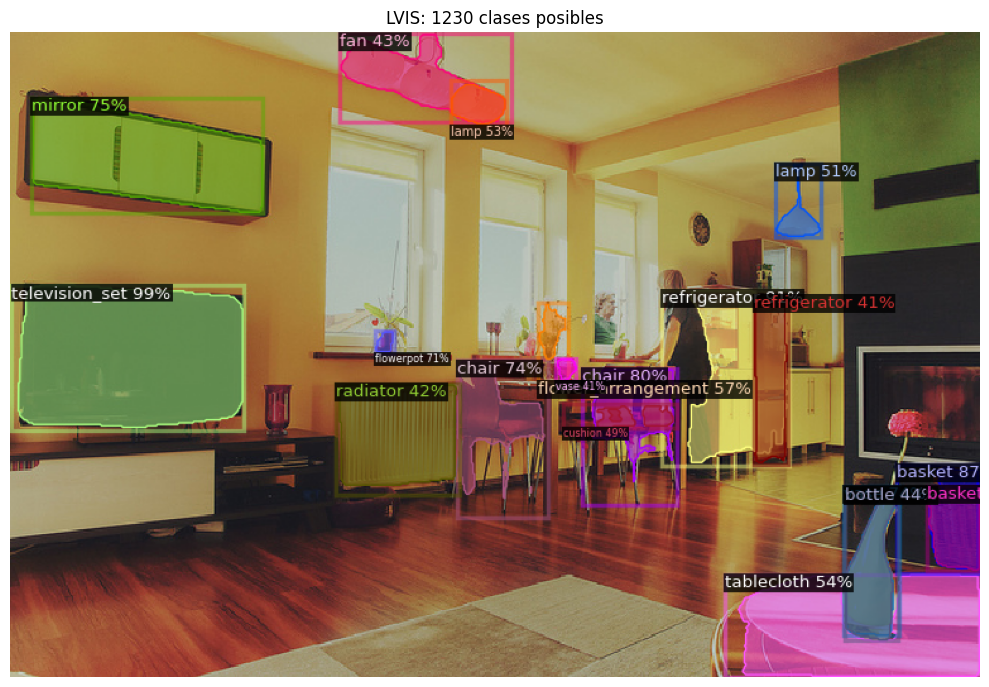

In [ ]:
try:
    CFG = "LVISv0.5-InstanceSegmentation/mask_rcnn_R_50_FPN_1x.yaml"
    im, out, meta = run(CFG, IMGS[2], thresh=0.4)
    r = Visualizer(im[:, :, ::-1], meta, scale=1.2).draw_instance_predictions(out["instances"].to("cpu")).get_image()
    show([r], [f"LVIS: {len(meta.thing_classes)} clases posibles"], size=10)
except Exception as e:
    print("LVIS no disponible:", e)

## 8. Comparar arquitecturas: velocidad vs. calidad

model_final_f6e8b1.pkl: 243MB [00:01, 185MB/s]                           
model_final_5bd44e.pkl: 152MB [00:02, 69.1MB/s]                           
  pixel_mean
  pixel_std


,modelo,detecciones,seg/imagen
0,faster_rcnn_R_50_FPN_3x,18,0.156
1,faster_rcnn_R_101_FPN_3x,17,0.194
2,retinanet_R_50_FPN_3x,13,0.175


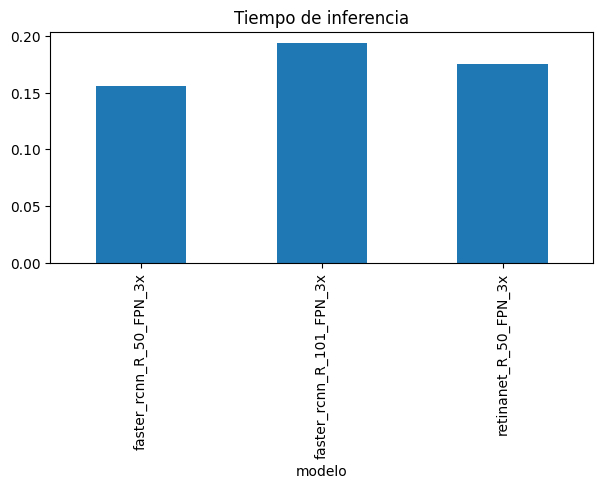

In [ ]:
configs = ["COCO-Detection/faster_rcnn_R_50_FPN_3x.yaml",
           "COCO-Detection/faster_rcnn_R_101_FPN_3x.yaml",
           "COCO-Detection/retinanet_R_50_FPN_3x.yaml"]
rows = []
for c in configs:
    cfg, pred = build(c)
    im = cv2.imread(IMGS[0]); pred(im)               # calentamiento
    t = time.time()
    for _ in range(5): out = pred(im)
    rows.append([c.split("/")[1].replace(".yaml", ""), len(out["instances"]), round((time.time()-t)/5, 3)])
df = pd.DataFrame(rows, columns=["modelo", "detecciones", "seg/imagen"]); display(df)
df.set_index("modelo")["seg/imagen"].plot.bar(figsize=(7, 3), title="Tiempo de inferencia"); plt.show()

## 9. Video: segmentación fotograma a fotograma

In [ ]:
import os
import urllib.request

# He cambiado esta opción a True para que por defecto solicite la subida de tu video.
USE_MY_VIDEO = True
VIDEO_IN = "input.mp4"

if USE_MY_VIDEO:
    print("Por favor, selecciona y sube tu archivo de video:")
    from google.colab import files
    up = files.upload()
    if up:
        nombre_subido = list(up.keys())[0]
        os.rename(nombre_subido, VIDEO_IN)
        print(f"\n¡Video listo! Guardado como {VIDEO_IN}")
    else:
        print("No se subió ningún archivo. Se buscará usar un video de ejemplo.")
else:
    # Si decides cambiar USE_MY_VIDEO a False, descargará automáticamente un video de tráfico urbano ideal para Detectron2
    print("Descargando video de ejemplo (Tráfico urbano y peatones)...")
    url_ejemplo = "https://github.com/intel-iot-devkit/sample-videos/raw/master/bottlenecks.mp4"
    try:
        urllib.request.urlretrieve(url_ejemplo, VIDEO_IN)
        print("Video de ejemplo descargado correctamente.")
    except Exception as e:
        print(f"Error al descargar el video de ejemplo: {e}")

Por favor, selecciona y sube tu archivo de video:


Saving 854671-hd_1920_1080_25fps.mp4 to 854671-hd_1920_1080_25fps.mp4

¡Video listo! Guardado como input.mp4


In [ ]:
from detectron2.utils.video_visualizer import VideoVisualizer
cfg, pred = build("COCO-InstanceSegmentation/mask_rcnn_R_50_FPN_3x.yaml", 0.5)
meta = MetadataCatalog.get(cfg.DATASETS.TRAIN[0])
vv = VideoVisualizer(meta, instance_mode=ColorMode.IMAGE)

cap = cv2.VideoCapture(VIDEO_IN)
fps = cap.get(cv2.CAP_PROP_FPS) or 10
W, H = int(cap.get(3)), int(cap.get(4))
writer = cv2.VideoWriter("raw.mp4",
                         cv2.VideoWriter_fourcc(*"mp4v"), fps, (W, H))
while True:
    ok, fr = cap.read()
    if not ok: break
    out = pred(fr)
    vis = vv.draw_instance_predictions(fr[:, :, ::-1],
                                       out["instances"].to("cpu"))
    writer.write(vis.get_image()[:, :, ::-1])
cap.release(); writer.release()
!ffmpeg -y -loglevel error -i raw.mp4 -vcodec libx264 output.mp4

from IPython.display import HTML
from base64 import b64encode
data = b64encode(open("output.mp4", "rb").read()).decode()
HTML(f'<video width=520 controls><source src="data:video/mp4;base64,{data}" type="video/mp4"></video>')

## 10. Entrenar con tus propios datos (dataset de globos)

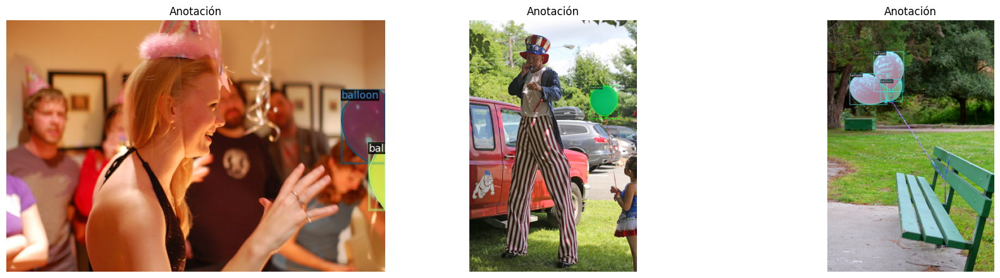

In [ ]:
!wget -q -nc https://github.com/matterport/Mask_RCNN/releases/download/v2.1/balloon_dataset.zip
!unzip -q -n balloon_dataset.zip

from detectron2.structures import BoxMode
from detectron2.data import DatasetCatalog

def get_balloon_dicts(img_dir):
    with open(os.path.join(img_dir, "via_region_data.json")) as f: ann = json.load(f)
    out = []
    for idx, v in enumerate(ann.values()):
        fn = os.path.join(img_dir, v["filename"]); h, w = cv2.imread(fn).shape[:2]
        objs = []
        for a in v["regions"].values():
            a = a["shape_attributes"]; px, py = a["all_points_x"], a["all_points_y"]
            poly = [c for p in zip(px, py) for c in (p[0]+0.5, p[1]+0.5)]
            objs.append({"bbox": [np.min(px), np.min(py), np.max(px), np.max(py)],
                         "bbox_mode": BoxMode.XYXY_ABS,
                         "segmentation": [poly], "category_id": 0})
        out.append({"file_name": fn, "image_id": idx, "height": h,
                    "width": w, "annotations": objs})
    return out

for d in ["train", "val"]:
    if f"balloon_{d}" in DatasetCatalog.list(): DatasetCatalog.remove(f"balloon_{d}")
    DatasetCatalog.register(f"balloon_{d}", lambda d=d: get_balloon_dicts(f"balloon/{d}"))
    MetadataCatalog.get(f"balloon_{d}").set(thing_classes=["balloon"])
bmeta = MetadataCatalog.get("balloon_train")

samples = random.sample(get_balloon_dicts("balloon/train"), 3)
show([Visualizer(cv2.imread(s["file_name"])[:, :, ::-1],
                 bmeta, scale=0.5).draw_dataset_dict(s).get_image() for s in samples],
     ["Anotación"]*3)

In [ ]:
from detectron2.engine import DefaultTrainer
cfg = get_cfg()
cfg.merge_from_file(model_zoo.get_config_file("COCO-InstanceSegmentation/mask_rcnn_R_50_FPN_3x.yaml"))
cfg.DATASETS.TRAIN, cfg.DATASETS.TEST = ("balloon_train",), ()
cfg.DATALOADER.NUM_WORKERS = 2
cfg.MODEL.WEIGHTS = model_zoo.get_checkpoint_url("COCO-InstanceSegmentation/mask_rcnn_R_50_FPN_3x.yaml")
cfg.SOLVER.IMS_PER_BATCH, cfg.SOLVER.BASE_LR, cfg.SOLVER.MAX_ITER = 2, 0.00025, 300
cfg.MODEL.ROI_HEADS.BATCH_SIZE_PER_IMAGE = 128
cfg.MODEL.ROI_HEADS.NUM_CLASSES = 1
if not torch.cuda.is_available(): cfg.MODEL.DEVICE = "cpu"
os.makedirs(cfg.OUTPUT_DIR, exist_ok=True)

trainer = DefaultTrainer(cfg)
trainer.resume_or_load(resume=False)
trainer.train()

[10/30 21:48:14 d2.engine.defaults]: Model:
GeneralizedRCNN(
  (backbone): FPN(
    (fpn_lateral2): Conv2d(256, 256, kernel_size=(1, 1), stride=(1, 1))
    (fpn_output2): Conv2d(256, 256, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (fpn_lateral3): Conv2d(512, 256, kernel_size=(1, 1), stride=(1, 1))
    (fpn_output3): Conv2d(256, 256, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (fpn_lateral4): Conv2d(1024, 256, kernel_size=(1, 1), stride=(1, 1))
    (fpn_output4): Conv2d(256, 256, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (fpn_lateral5): Conv2d(2048, 256, kernel_size=(1, 1), stride=(1, 1))
    (fpn_output5): Conv2d(256, 256, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (top_block): LastLevelMaxPool()
    (bottom_up): ResNet(
      (stem): BasicStem(
        (conv1): Conv2d(
          3, 64, kernel_size=(7, 7), stride=(2, 2), padding=(3, 3), bias=False
          (norm): FrozenBatchNorm2d(num_features=64, eps=1e-05)
        )
      )
      (res

roi_heads.box_predictor.bbox_pred.{bias, weight}
roi_heads.box_predictor.cls_score.{bias, weight}
roi_heads.mask_head.predictor.{bias, weight}


[10/30 21:48:15 d2.engine.train_loop]: Starting training from iteration 0
[10/30 21:48:28 d2.utils.events]:  eta: 0:02:48  iter: 19  total_loss: 2.024  loss_cls: 0.6187  loss_box_reg: 0.5798  loss_mask: 0.6872  loss_rpn_cls: 0.03279  loss_rpn_loc: 0.01076    time: 0.5763  last_time: 0.6486  data_time: 0.0183  last_data_time: 0.0070   lr: 1.6068e-05  max_mem: 3790M
[10/30 21:48:45 d2.utils.events]:  eta: 0:02:27  iter: 39  total_loss: 1.81  loss_cls: 0.5296  loss_box_reg: 0.6005  loss_mask: 0.5951  loss_rpn_cls: 0.04477  loss_rpn_loc: 0.006598    time: 0.5657  last_time: 0.5179  data_time: 0.0073  last_data_time: 0.0055   lr: 3.2718e-05  max_mem: 3861M
[10/30 21:48:56 d2.utils.events]:  eta: 0:02:16  iter: 59  total_loss: 1.657  loss_cls: 0.4442  loss_box_reg: 0.7557  loss_mask: 0.493  loss_rpn_cls: 0.01995  loss_rpn_loc: 0.009155    time: 0.5643  last_time: 0.4875  data_time: 0.0091  last_data_time: 0.0142   lr: 4.9367e-05  max_mem: 3912M
[10/30 21:49:08 d2.utils.events]:  eta: 0:02:09

[10/30 21:53:32 d2.checkpoint.detection_checkpoint]: [DetectionCheckpointer] Loading from ./output/model_final.pth ...


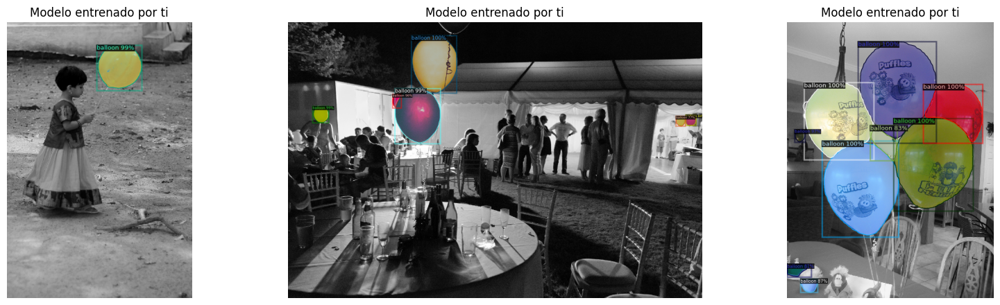

In [ ]:
cfg.MODEL.WEIGHTS = os.path.join(cfg.OUTPUT_DIR, "model_final.pth")
cfg.MODEL.ROI_HEADS.SCORE_THRESH_TEST = 0.7
cfg.DATASETS.TEST = ("balloon_val",)
pred = DefaultPredictor(cfg)

ims = []
for s in random.sample(get_balloon_dicts("balloon/val"), 3):
    im = cv2.imread(s["file_name"]); out = pred(im)
    ims.append(Visualizer(im[:, :, ::-1], bmeta, scale=0.6,
                          instance_mode=ColorMode.IMAGE_BW)
               .draw_instance_predictions(out["instances"].to("cpu")).get_image())
show(ims, ["Modelo entrenado por ti"]*3)

### Evaluación (AP)

In [ ]:
from detectron2.evaluation import COCOEvaluator, inference_on_dataset
from detectron2.data import build_detection_test_loader
ev = COCOEvaluator("balloon_val", output_dir="./output")
res = inference_on_dataset(pred.model, build_detection_test_loader(cfg, "balloon_val"), ev)
pd.DataFrame(res["segm"], index=["AP"]).round(2)

[10/30 21:53:41 d2.evaluation.coco_evaluation]: Trying to convert 'balloon_val' to COCO format ...
[10/30 21:53:41 d2.data.datasets.coco]: Converting annotations of dataset 'balloon_val' to COCO format ...)
[10/30 21:53:41 d2.data.datasets.coco]: Converting dataset dicts into COCO format
[10/30 21:53:41 d2.data.datasets.coco]: Conversion finished, #images: 13, #annotations: 50
[10/30 21:53:41 d2.data.datasets.coco]: Caching COCO format annotations at './output/balloon_val_coco_format.json' ...
[10/30 21:53:41 d2.data.build]: Distribution of instances among all 1 categories:
|  category  | #instances   |
|:----------:|:-------------|
|  balloon   | 50           |
|            |              |
[10/30 21:53:41 d2.data.dataset_mapper]: [DatasetMapper] Augmentations used in inference: [ResizeShortestEdge(short_edge_length=(800, 800), max_size=1333, sample_style='choice')]
[10/30 21:53:41 d2.data.common]: Serializing the dataset using: <class 'detectron2.data.common._TorchSerializedList'>
[1

,AP,AP50,AP75,APs,APm,APl
AP,78.7,85.26,85.26,0.0,58.97,95.28


## ✅ Resumen
| Tarea | Config del Model Zoo |
|---|---|
| Detección | `COCO-Detection/faster_rcnn_*` |
| Segmentación de instancias | `COCO-InstanceSegmentation/mask_rcnn_*` |
| Keypoints | `COCO-Keypoints/keypoint_rcnn_*` |
| Panóptica | `COCO-PanopticSegmentation/panoptic_fpn_*` |
| LVIS (1000+ clases) | `LVISv0.5-InstanceSegmentation/*` |
| Entrenar propio | `DefaultTrainer` + dataset registrado |